# 04 · EMT-TF Expression — Giustacchini 2017 CML

The unconditional final step: overlay the most informative EMT transcription factors on the trajectory.
Candidates are scored on **this dataset** and gated on detectable expression (>3% of cells), spanning
the Snail / Zeb / Twist / FOXC / PRRX families rather than a fixed pair. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 1845 | pseudotime range 0.0 -> 11.82


### Candidate EMT-TF panel — scored on this dataset, gated on detection
Score each candidate by expressing fraction and by early/late (root/terminus) mean, take the expressed
factors (>3%), and read the pair spanning the axis. Only **ZEB1** and **ZEB2** clear the detection gate
here; the Snail/Twist/FOXC/PRRX candidates are essentially undetected in this SmartSeq2 CML cohort.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
print('candidate TFs present in data:', present)
print('candidate TFs absent:', [g for g in panel if g not in adata.var_names])
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nexpressed TFs (>3%): {ok.TF.tolist()}')
print(f'derived pair: {early_tf} (earlier) <-> {late_tf} (terminus)')

candidate TFs present in data: ['SNAI1', 'ZEB1', 'ZEB2', 'TWIST1', 'FOXC1', 'PRRX1']
candidate TFs absent: ['SNAI2', 'TWIST2', 'FOXC2', 'PRRX2']
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 PRRX1      0.002       0.001      0.000    -0.048    EARLY(root)
TWIST1      0.002       0.009      0.002    -0.031    EARLY(root)
 FOXC1      0.003       0.000      0.005     0.007 LATE(terminus)
 SNAI1      0.014       0.028      0.034     0.059 LATE(terminus)
  ZEB1      0.244       0.216      0.480     0.192 LATE(terminus)
  ZEB2      0.425       0.592      1.326     0.246 LATE(terminus)

expressed TFs (>3%): ['ZEB1', 'ZEB2']
derived pair: ZEB1 (earlier) <-> ZEB2 (terminus)


### EMT-TF overlay — thresholded expressers on the trajectory
Categorical overlay (reference style): cells expressing each TF above its upper-quartile-among-expressers
threshold are coloured on a grey manifold, the larger group drawn first.

overlay thresholds (upper quartile among expressers): {'ZEB1': 2.635, 'ZEB2': 3.94} | cells shown: {'ZEB1': 113, 'ZEB2': 196}
ZEB1: 24.4% expressing; 113 shown (upper quartile), mean pseudotime of shown cells = 0.61 (all cells = 0.49)
ZEB2: 42.5% expressing; 196 shown (upper quartile), mean pseudotime of shown cells = 0.57 (all cells = 0.49)
saved expression.pdf


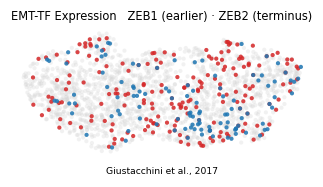

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (earlier) \u00b7 {late_tf} (terminus)', size=7.5)
ax.text(.5,-.14,'Giustacchini et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
print('saved expression.pdf')